In [18]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense,Dropout

In [20]:
data=pd.read_csv('nifty50.csv',header=None,skiprows=3,usecols=[0,2],names=['Date','Close'])
date=pd.to_datetime(data['Date'])
price=pd.to_numeric(data['Close']).values.reshape(-1,1)
scaler=MinMaxScaler()
scaled_data=scaler.fit_transform(price)
x,y=[],[]
for i in range(60,len(scaled_data)):
    x.append(scaled_data[i-60:i,0])
    y.append(scaled_data[i,0])
x=np.array(x).reshape(-1,60,1)
y=np.array(y)

trainsize=int(len(x)*0.80)

xtrain,xtest=x[:trainsize],x[trainsize :]
ytrain,ytest=y[:trainsize],y[trainsize:]

model=Sequential([LSTM(64,return_sequences=True,input_shape=(60,1)),
                 Dropout(0.2),
                 LSTM(64),
                 Dense(32),
                 Dense(1)])
model.compile(loss='mae',optimizer='adam')
model.fit(xtrain,ytrain,epochs=20,batch_size=32)
pred=scaler.inverse_transform(model.predict(xtest)).flatten()

actual=price[60+trainsize:].flatten()
test_date=date.iloc[60+trainsize:]

plt.figure(figsize=(10,8))
plt.plot(date,price.flatten())
plt.plot(test_date,actual)
plt.plot(test_date,pred)

C:\Users\SHYAM HARI\Desktop\python ml ds\bootcamp\tf2\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 11s 84ms/step - loss: 0.0839
Epoch 2/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - loss: 0.0149
Epoch 3/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - loss: 0.0145
Epoch 4/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - loss: 0.0128
Epoch 5/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - loss: 0.0132
Epoch 6/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - loss: 0.0119
Epoch 7/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - loss: 0.0135
Epoch 8/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - loss: 0.0116
Epoch 9/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 0.0139
Epoch 10/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - loss: 0.0112
Epoch 11/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - loss: 0.0119
Epoch 12/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - loss: 0.0102
Epoch 13/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - loss: 0.0119
Epoch 14/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - loss: 0.0105
Epoch 15/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - loss: 0.0118
Epo

NameError: name 'plt' is not defined

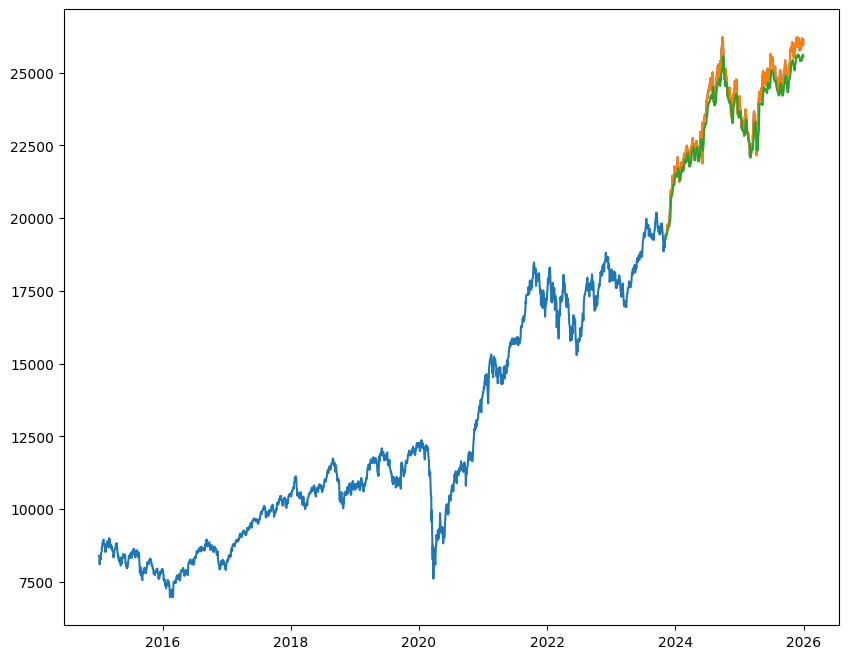

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
plt.plot(date,price.flatten())
plt.plot(test_date,actual)
plt.plot(test_date,pred)